# C08a — Six competitor humanizers against Binoculars NF4

Run in a **fresh kernel in the same environment as the successful C07a NF4 experiment**. No rewrites or humanizer training are performed. The notebook reads all six saved C08 rewrite sets and reuses C07a's content-addressed Binoculars scores for OG, NS10, human references and original RAID training rows. Only missing documents are scored.

**Protocol:** frozen Falcon-7B / Falcon-7B-Instruct, NF4 with BF16 compute, original 512-token prefix and score orientation (AI score = negative Binoculars ratio). This is the existing quantized variant, not full-precision published Binoculars. Do not apply full-precision published thresholds as calibrated operating points.

All eight arms (OG, NS10 and six competitors) appear on one 54-case staircase figure. Select competitors with full-cohort frozen-ratio AUROC **strictly below .8** for adaptation. Each selected method gets its own classifier trained on original RAID data plus twenty examples from that method. A common saved 20/34 source split applies to every method. No cross-arm training.

Binoculars itself has no learned classifier to retrain. Following C07a, adaptation fits balanced logistic regression on `mean_nll` and `cross_entropy`, with a scaler fitted on original RAID training data only. We plot frozen ratio, RAID-only readout and own-attack adapted readout. The RAID-only control isolates changing the decision rule from learning from attack exposure. Falcon weights remain frozen.

Selection uses all 54 outcomes, including the eventual 34 evaluation cases: this is an exploratory conditional comparison, not a fully independent selection/validation experiment. Human-domain weights match each evaluated cohort. Each decision rule is calibrated separately using validation humans; test humans are reserved for evaluation.

Models load sequentially. Observer logits use bounded **disk** batches; each final score is saved immediately, then its temporary logits are deleted. Batch size controls disk use, not GPU batching. Existing C07a score caches are shared; C08a tables, splits, trained readouts and figures are separate. Do not run C07a scoring concurrently.

References: [Binoculars](https://github.com/ahans30/Binoculars); source metric implementation pinned to C07a commit `c8ae2f90d50ee696418bc71d8d9e5020e5f9d7b8`. Keep the existing tested dependency versions. Figures save as PNG/PDF both in the result directory and `reproduction/figures/`.


In [1]:
# %pip install "transformers==4.44.2" "accelerate==0.34.2"

In [2]:
from pathlib import Path
import os,json,hashlib,tempfile,time,getpass,math
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve,auc
from IPython.display import display
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
 if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()),None)
assert ROOT is not None,'Run inside the reproduction project.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
# Use the output directory of your successful NF4 run.
OUT=ROOT/'results/causal/C07a_Binoculars_NF4_OG_NS10_pinned_v1'
if not (OUT/'contract.json').exists():
 OUT=ROOT/'results/causal/C07a_Binoculars_NF4_OG_NS10_v1'
assert (OUT/'contract.json').exists(), 'Set OUT to your completed NF4 run directory.'
ADAPT=ROOT/'results/causal/C08a_Binoculars_competitors_NF4_v1';ADAPT.mkdir(parents=True,exist_ok=True)
ADAPT_SEED=20260923
OUT.mkdir(parents=True,exist_ok=True)
CACHE=OUT/'responses';CACHE.mkdir(exist_ok=True)
SEED=20260922
MAX_TOKENS=512
DELETE_CONSUMED_LOGITS=True
OBSERVER='tiiuae/falcon-7b'
PERFORMER='tiiuae/falcon-7b-instruct'
LOGITS=OUT/'observer_logits';LOGITS.mkdir(exist_ok=True)
import gc,shutil,importlib.metadata
import torch
from transformers import AutoTokenizer,AutoModelForCausalLM,AutoConfig,BitsAndBytesConfig
from huggingface_hub import HfApi
assert torch.cuda.is_available(), 'This configuration needs a CUDA GPU.'
assert torch.cuda.is_bf16_supported(), 'BF16 required; do not silently change detector precision.'

def text_sha(t):return hashlib.sha256(str(t).encode()).hexdigest()
def file_sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def atomic(path,data):
 fd,tmp=tempfile.mkstemp(dir=Path(path).parent,suffix='.tmp')
 try:
  with os.fdopen(fd,'wb') as f:f.write(data);f.flush();os.fsync(f.fileno())
  os.replace(tmp,path)
 finally:
  if os.path.exists(tmp):os.unlink(tmp)
def save_json(obj,p):atomic(p,json.dumps(obj,sort_keys=True,indent=2,allow_nan=False).encode())
def save_csv(df,p):atomic(p,df.to_csv(index=False).encode())
def freeze(obj,p):
 if p.exists():assert json.loads(p.read_text())==obj,'Protocol changed; use a new OUT directory.'
 else:save_json(obj,p)

import bitsandbytes,psutil
print(f"Available RAM: {psutil.virtual_memory().available/2**30:.2f} GiB")
print(f"Free GPU memory: {torch.cuda.mem_get_info()[0]/2**30:.2f} GiB")

SCORE_BATCH_SIZE=32  # disk batch only; GPU inference remains one document at a time


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Available RAM: 22.70 GiB
Free GPU memory: 6.43 GiB


In [3]:
# Resolve the exact C05 data universe through saved doc keys.
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
keys=pd.read_parquet(C05/'raid_all_features.parquet',columns=['doc_key']).doc_key
expected='raid::'+raid.source_id.astype(str)
assert keys.is_unique and set(keys)==set(expected), 'C05 dataset mismatch'
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.astype(str).str.strip().ne('').all()
assert set(raid.split)=={'train','validation','test'}
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(text_sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)


raid['pair_group_id']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('pair_group_id').split.nunique().eq(1).all()
h=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])].copy()
h['case_id']='';h['stage']='Human'
o=og.assign(stage='OG',split='test',label=1)
n=ns[['case_id','source_id','domain','text']].assign(stage='NS10',split='test',label=1)
train_rows=raid.loc[raid.split.eq('train')].copy()
train_rows['case_id']='';train_rows['stage']='RAID_train'
docs=pd.concat([h,o,n,train_rows],ignore_index=True)
docs['text_sha']=docs.text.map(text_sha)
docs['words']=docs.text.str.split().str.len()
unique=docs[['text_sha','text','words']].drop_duplicates('text_sha').reset_index(drop=True)
display(docs.groupby(['stage','split']).size().rename('documents'))

# Release larger source tables before model loading; docs/unique retain evaluation texts.
del meta,corpus,raid,rm,h,o,n,keys,expected
gc.collect()


C08=ROOT/'results/causal/C08_Ghostbuster_only_RAID54_v1'
RELEASED=C08/'released_checkpoints_v1'
FILES={
 'HIP_RAID_0.6B':C08/'HIP_RAID_0.6B_texts.csv',
 'MASH_RAID_GB':C08/'MASH_RAID_GB_texts.csv',
 'UTS_SYNTH_RECON':C08/'UTS_SYNTH_RECON_texts.csv',
 'UTS_STREAM_RECON':C08/'UTS_STREAM_RECON_texts.csv',
 'HIP_RELEASED_4B':RELEASED/'HIP_RELEASED_4B_texts.csv',
 'StealthRL_RELEASED_4B':RELEASED/'StealthRL_RELEASED_4B_texts.csv',
}
ARMS=list(FILES)
LABELS=dict(zip(ARMS,['HIP limited','MASH limited','UTS SYNTH limited','UTS STREAM limited','HIP released 4B','StealthRL released 4B']))
extras=[];input_manifest=[]
for arm,path in FILES.items():
 assert path.exists(),f'Missing completed C08 rewrite export: {path}'
 f=pd.read_csv(path,keep_default_na=False)
 assert len(f)==54 and f.case_id.is_unique and set(f.case_id)==set(ns.case_id)
 f=f.set_index('case_id').loc[ns.case_id].reset_index()
 assert f.source_id.astype(str).tolist()==ns.source_id.astype(str).tolist()
 assert f.domain.tolist()==ns.domain.tolist() and f.text.str.strip().ne('').all()
 if 'text_sha' in f:assert f.text_sha.eq(f.text.map(text_sha)).all()
 for r in f.itertuples():input_manifest.append(dict(arm=arm,case_id=r.case_id,source_id=r.source_id,text_sha=text_sha(r.text)))
 extras.append(f[['case_id','source_id','domain','text']].assign(stage=arm,split='test',label=1))
freeze(input_manifest,ADAPT/'rewrite_inputs.json')
docs=pd.concat([docs,*extras],ignore_index=True)
docs['text_sha']=docs.text.map(text_sha);docs['words']=docs.text.str.split().str.len()
unique=docs[['text_sha','text','words']].drop_duplicates('text_sha').reset_index(drop=True)
case_ids=sorted(ns.case_id.astype(str).tolist())
chosen=sorted(np.random.default_rng(ADAPT_SEED).choice(case_ids,size=20,replace=False).tolist())
held=sorted(set(case_ids)-set(chosen))
freeze(dict(seed=ADAPT_SEED,adaptation_cases=chosen,test_cases=held),ADAPT/'split.json')
roles=ns[['case_id','source_id','domain']].copy()
roles['role']=np.where(roles.case_id.isin(chosen),'adaptation','heldout')
save_csv(roles,ADAPT/'case_roles.csv')
assert not set(docs.loc[docs.stage.eq('RAID_train'),'source_id'])&set(ns.source_id)
for arm in ARMS:
 fit=docs.loc[docs.stage.eq('RAID_train')|(docs.stage.eq(arm)&docs.case_id.isin(chosen))]
 test=docs.loc[docs.stage.eq('Human')|(docs.stage.eq(arm)&docs.case_id.isin(held))]
 assert not set(fit.text_sha)&set(test.text_sha),f'Exact fitting/evaluation text overlap: {arm}'
display(docs.groupby('stage').size().rename('documents'))
display(pd.crosstab(roles.domain,roles.role))
del extras,train_rows


stage       split     
Human       test           138
            validation     135
NS10        test            54
OG          test            54
RAID_train  train         1272
Name: documents, dtype: int64

stage
HIP_RAID_0.6B              54
HIP_RELEASED_4B            54
Human                     273
MASH_RAID_GB               54
NS10                       54
OG                         54
RAID_train               1272
StealthRL_RELEASED_4B      54
UTS_STREAM_RECON           54
UTS_SYNTH_RECON            54
Name: documents, dtype: int64

role,adaptation,heldout
domain,,
abstracts,3,7
books,2,5
news,7,5
recipes,4,5
reddit,2,4
reviews,0,1
wiki,2,7


## Restore the exact C07a scoring contract
A runtime/contract mismatch requires restoring the working C07a environment. Do not overwrite the old contract to force reuse of incompatible scores.

In [4]:
# Freeze model revisions and score/cache contract before downloading weights.
revpath=OUT/'model_revisions.json'
if revpath.exists():revisions=json.loads(revpath.read_text())
else:
 prior=ROOT/'results/causal/C07a_Binoculars_OG_NS10_v1/model_revisions.json'
 revisions=json.loads(prior.read_text()) if prior.exists() else {name:HfApi().model_info(name).sha for name in [OBSERVER,PERFORMER]}
 save_json(revisions,revpath)
tok=AutoTokenizer.from_pretrained(OBSERVER,revision=revisions[OBSERVER])
other=AutoTokenizer.from_pretrained(PERFORMER,revision=revisions[PERFORMER])
assert tok.vocab==other.vocab,'The model tokenizers must share their vocabulary.'
if tok.pad_token is None:tok.pad_token=tok.eos_token
del other
contract=dict(version='C07a_Binoculars_NF4_v1',quantization='NF4_double_quant',metric_device='cpu',models=revisions,max_tokens=MAX_TOKENS,
 dtype='bfloat16',attention='eager',metric='official_mean_nll_over_cross_entropy',
 code_commit='c8ae2f90d50ee696418bc71d8d9e5020e5f9d7b8',
 runtime={p:importlib.metadata.version(p) for p in ['torch','transformers','accelerate','bitsandbytes']},
 inputs={str(p.relative_to(ROOT)):file_sha(p) for p in [BASE/'fz118_paired_features.parquet',
 BASE/'paired_corpus.parquet',C05/'raid_all_features.parquet',NSDIR/'NS10_texts.csv']})
freeze(contract,OUT/'contract.json');signature=text_sha(json.dumps(contract,sort_keys=True))
def cache_path(sha):return CACHE/(text_sha(signature+sha)+'.json')
def logit_path(sha):return LOGITS/(text_sha(signature+sha)+'.pt')
def encode(text):return tok(text,return_tensors='pt',truncation=True,max_length=MAX_TOKENS)
def complete(sha):
 p=cache_path(sha)
 if not p.exists():return False
 r=json.loads(p.read_text())
 assert r['contract']==signature and r['text_sha']==sha and np.isfinite(r['Binoculars_score'])
 return True
lengths={r.text_sha:len(tok(r.text,truncation=False)['input_ids']) for r in unique.itertuples()}
assert min(lengths.values())>=2,'A document has fewer than two tokens; inspect rather than silently excluding it.'
docs['total_tokens']=docs.text_sha.map(lengths)
docs['scored_tokens']=docs.total_tokens.clip(upper=MAX_TOKENS)
docs['truncated']=docs.total_tokens.gt(MAX_TOKENS)
save_csv(docs.drop(columns='text'),ADAPT/'score_manifest.csv')
display(docs.groupby('stage').agg(documents=('text_sha','size'),truncated=('truncated','sum')))
vocab=AutoConfig.from_pretrained(OBSERVER,revision=revisions[OBSERVER]).vocab_size
missing=[r for r in unique.to_dict('records') if not complete(r['text_sha'])]
next_batch=missing[:SCORE_BATCH_SIZE]
needed=sum(min(lengths[r['text_sha']],MAX_TOKENS)*vocab*4 for r in next_batch if not logit_path(r['text_sha']).exists())
print(f'Pending scores: {len(missing)}; next-batch extra observer cache: {needed/2**30:.2f} GiB')
print(f'Free disk space: {shutil.disk_usage(OUT).free/2**30:.1f} GiB')
assert shutil.disk_usage(OUT).free>needed+2*2**30,'Insufficient disk space for next batch; reduce SCORE_BATCH_SIZE.'


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


,documents,truncated
stage,,
HIP_RAID_0.6B,54,17
HIP_RELEASED_4B,54,6
Human,273,11
MASH_RAID_GB,54,8
NS10,54,25
OG,54,1
RAID_train,1272,51
StealthRL_RELEASED_4B,54,0
UTS_STREAM_RECON,54,24


Pending scores: 0; next-batch extra observer cache: 0.00 GiB
Free disk space: 258.9 GiB


In [5]:
# Default metric functions from the pinned official implementation (see reference above).
import numpy as np
import torch
import transformers

ce_loss_fn = torch.nn.CrossEntropyLoss(reduction="none")
softmax_fn = torch.nn.Softmax(dim=-1)


def perplexity(encoding: transformers.BatchEncoding,
               logits: torch.Tensor,
               median: bool = False,
               temperature: float = 1.0):
    shifted_logits = logits[..., :-1, :].contiguous() / temperature
    shifted_labels = encoding.input_ids[..., 1:].contiguous()
    shifted_attention_mask = encoding.attention_mask[..., 1:].contiguous()

    if median:
        ce_nan = (ce_loss_fn(shifted_logits.transpose(1, 2), shifted_labels).
                  masked_fill(~shifted_attention_mask.bool(), float("nan")))
        ppl = np.nanmedian(ce_nan.cpu().float().numpy(), 1)

    else:
        ppl = (ce_loss_fn(shifted_logits.transpose(1, 2), shifted_labels) *
               shifted_attention_mask).sum(1) / shifted_attention_mask.sum(1)
        ppl = ppl.to("cpu").float().numpy()

    return ppl


def entropy(p_logits: torch.Tensor,
            q_logits: torch.Tensor,
            encoding: transformers.BatchEncoding,
            pad_token_id: int,
            median: bool = False,
            sample_p: bool = False,
            temperature: float = 1.0):
    vocab_size = p_logits.shape[-1]
    total_tokens_available = q_logits.shape[-2]
    p_scores, q_scores = p_logits / temperature, q_logits / temperature

    p_proba = softmax_fn(p_scores).view(-1, vocab_size)

    if sample_p:
        p_proba = torch.multinomial(p_proba.view(-1, vocab_size), replacement=True, num_samples=1).view(-1)

    q_scores = q_scores.view(-1, vocab_size)

    ce = ce_loss_fn(input=q_scores, target=p_proba).view(-1, total_tokens_available)
    padding_mask = (encoding.input_ids != pad_token_id).type(torch.uint8)

    if median:
        ce_nan = ce.masked_fill(~padding_mask.bool(), float("nan"))
        agg_ce = np.nanmedian(ce_nan.cpu().float().numpy(), 1)
    else:
        agg_ce = (((ce * padding_mask).sum(1) / padding_mask.sum(1)).to("cpu").float().numpy())

    return agg_ce


In [6]:
def save_tensor(obj,path):
 fd,tmp=tempfile.mkstemp(dir=path.parent,suffix='.tmp');os.close(fd)
 try:
  torch.save(obj,tmp)
  with open(tmp,'rb') as f:os.fsync(f.fileno())
  os.replace(tmp,path)
 finally:
  if os.path.exists(tmp):os.unlink(tmp)
def load_model(name):
 print('Loading',name,flush=True)
 quant=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
  bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=torch.bfloat16)
 model=AutoModelForCausalLM.from_pretrained(name,revision=revisions[name],
  torch_dtype=torch.bfloat16,quantization_config=quant,device_map={'':0},
  low_cpu_mem_usage=True,attn_implementation='eager')
 print(f'Model footprint: {model.get_memory_footprint()/2**30:.2f} GiB',flush=True)
 model.eval();return model
@torch.inference_mode()
def forward(model,encoding):
 # Accelerate dispatch hooks move inputs to the execution device as necessary.
 device=model.get_input_embeddings().weight.device
 if device.type=='meta':device=torch.device('cuda:0')
 return model(**{k:v.to(device) for k,v in encoding.items()},use_cache=False).logits.detach().cpu()



## Score missing documents — resumable
The first run scores up to 324 new rewrite documents. The adaptation training corpus is reused from C07a when cached. This is scoring, not text generation; it can still take substantial time on the laptop GPU.

In [7]:
import fcntl
with (OUT/'binoculars_scoring.lock').open('a') as score_lock:
    fcntl.flock(score_lock,fcntl.LOCK_EX | fcntl.LOCK_NB)
    # Alternate model passes over bounded batches; final scores retain the same contract.
    # Existing completed scores and observer logits are reusable.
    all_pending=[r for r in unique.to_dict('records') if not complete(r['text_sha'])]
    for start in range(0,len(all_pending),SCORE_BATCH_SIZE):
     batch=all_pending[start:start+SCORE_BATCH_SIZE]
     print(f'Batch {start//SCORE_BATCH_SIZE+1}: {len(batch)} documents',flush=True)
     observer_pending=[r for r in batch if not complete(r['text_sha']) and not logit_path(r['text_sha']).exists()]
     needed=sum(min(lengths[r['text_sha']],MAX_TOKENS)*vocab*4 for r in observer_pending)
     assert shutil.disk_usage(OUT).free>needed+2*2**30,'Disk space low; reduce SCORE_BATCH_SIZE and rerun.'
     model=None
     try:
      if observer_pending:model=load_model(OBSERVER)
      for r in tqdm(observer_pending,desc='Observer batch'):
       enc=encode(r['text']);p=forward(model,enc)
       save_tensor(dict(contract=signature,text_sha=r['text_sha'],ids=enc.input_ids,logits=p),logit_path(r['text_sha']))
       del p,enc
     finally:
      del model;gc.collect();torch.cuda.empty_cache()
     model=None
     try:
      pending=[r for r in batch if not complete(r['text_sha'])]
      if pending:model=load_model(PERFORMER)
      for r in tqdm(pending,desc='Performer batch'):
       started=time.perf_counter();enc=encode(r['text'])
       saved=torch.load(logit_path(r['text_sha']),map_location='cpu',weights_only=True)
       assert saved['contract']==signature and saved['text_sha']==r['text_sha']
       assert torch.equal(saved['ids'],enc.input_ids)
       q=forward(model,enc);p=saved['logits']
       with torch.inference_mode():
        numerator=float(perplexity(enc,q)[0]);denominator=float(entropy(p,q,enc,tok.pad_token_id)[0])
       assert np.isfinite(numerator) and np.isfinite(denominator) and denominator>0
       ratio=numerator/denominator
       save_json(dict(contract=signature,text_sha=r['text_sha'],Binoculars_score=ratio,AI_score=-ratio,
        mean_nll=numerator,cross_entropy=denominator,scored_tokens=int(enc.input_ids.shape[1]),
        total_tokens=lengths[r['text_sha']],seconds=time.perf_counter()-started),cache_path(r['text_sha']))
       # Delete only after the final score is durably saved.
       logit_path(r['text_sha']).unlink(missing_ok=True)
       del p,q,enc,saved
     finally:
      del model;gc.collect();torch.cuda.empty_cache()
     print(f'Completed {min(start+SCORE_BATCH_SIZE,len(all_pending))}/{len(all_pending)} initially pending scores',flush=True)
    records=[]
    for r in docs.drop(columns='text').to_dict('records'):
     assert complete(r['text_sha'])
     records.append({**r,**json.loads(cache_path(r['text_sha']).read_text())})
    scored=pd.DataFrame(records);save_csv(scored,ADAPT/'all_scores.csv')
    print('Saved training and evaluation component scores.')


Saved training and evaluation component scores.


## Full-cohort comparison and automatic adaptation selection

,arm,detector,cases,AUROC,mean_AI_score
0,OG,Frozen ratio,54,0.905163,-0.765013
1,NS10,Frozen ratio,54,0.721606,-0.919246
2,HIP_RAID_0.6B,Frozen ratio,54,0.892028,-0.818187
3,MASH_RAID_GB,Frozen ratio,54,0.851328,-0.893905
4,UTS_SYNTH_RECON,Frozen ratio,54,0.879499,-0.845388
5,UTS_STREAM_RECON,Frozen ratio,54,0.965326,-0.783344
6,HIP_RELEASED_4B,Frozen ratio,54,0.918052,-0.856037
7,StealthRL_RELEASED_4B,Frozen ratio,54,0.381898,-1.031138


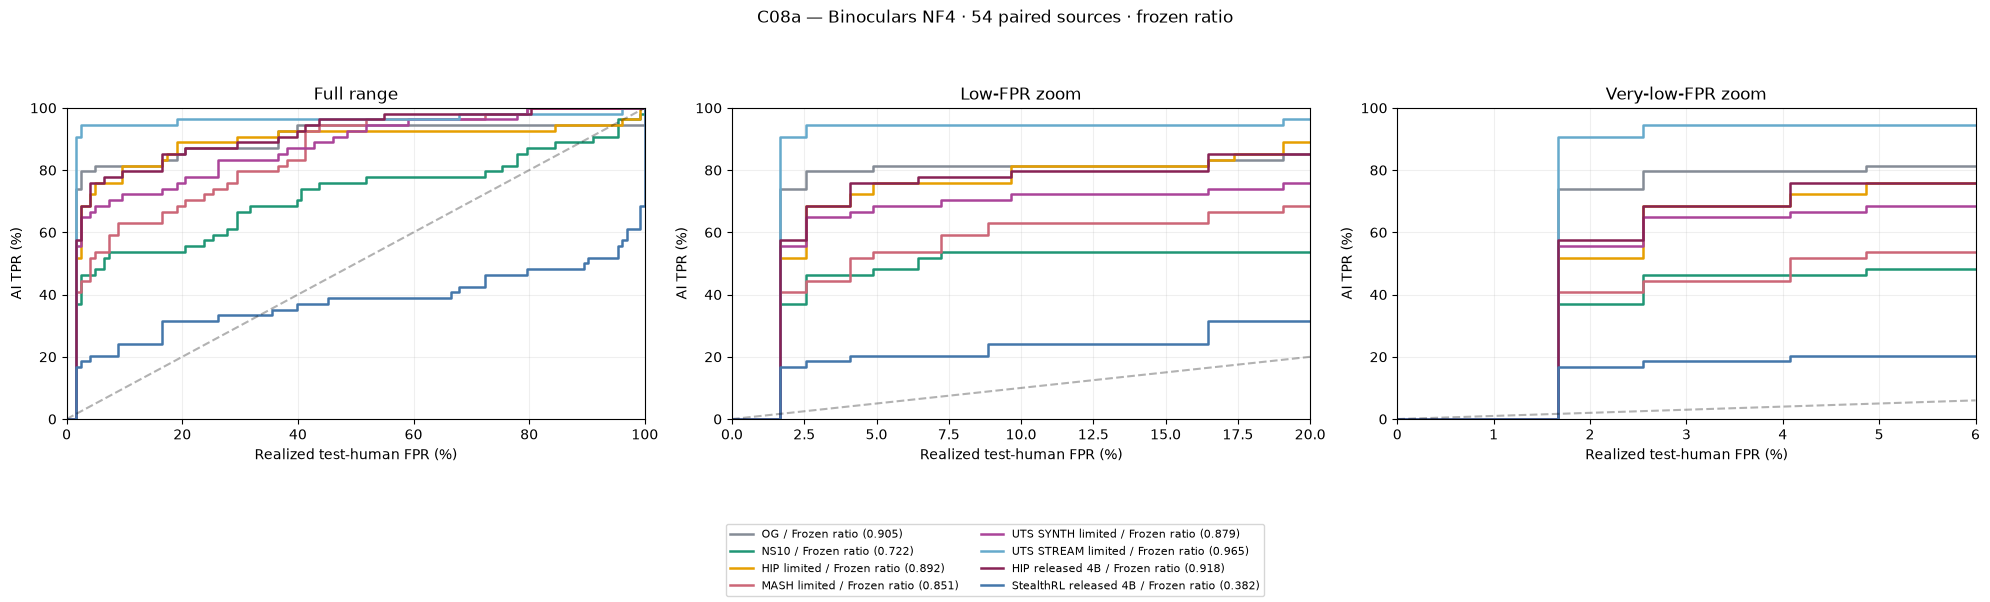

,arm,reference,delta_AUROC,ci_low,ci_high
0,HIP_RAID_0.6B,OG,-0.013135,-0.096163,0.070868
1,HIP_RAID_0.6B,NS10,0.170422,0.062185,0.274545
2,MASH_RAID_GB,OG,-0.053835,-0.136290,0.030931
3,MASH_RAID_GB,NS10,0.129721,0.027631,0.231653
4,UTS_SYNTH_RECON,OG,-0.025664,-0.080972,0.029713
5,UTS_SYNTH_RECON,NS10,0.157893,0.072771,0.247417
6,UTS_STREAM_RECON,OG,0.060164,0.004065,0.125149
7,UTS_STREAM_RECON,NS10,0.243720,0.151309,0.335790
8,HIP_RELEASED_4B,OG,0.012889,-0.036605,0.066889
9,HIP_RELEASED_4B,NS10,0.196446,0.101412,0.294885


Selected for own-attack adaptation: ['StealthRL_RELEASED_4B']
Selection uses all 54 scores: subsequent 34-case adaptation analysis is exploratory, not an independent selection holdout.


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
import warnings
import joblib

H=scored.loc[scored.stage.eq('Human')].copy()
T=scored.loc[scored.stage.eq('RAID_train')].copy()
FEATURES=['mean_nll','cross_entropy']
assert np.isfinite(scored[FEATURES].to_numpy(float)).all()

def references(e):
    mix=e.domain.value_counts(normalize=True)
    def get(split):
        f=H.loc[H.split.eq(split)&H.domain.isin(mix.index)].copy()
        counts=f.domain.value_counts()
        assert set(mix.index)<=set(counts.index)
        f['weight']=[mix[d]/counts[d] for d in f.domain]
        assert np.isclose(f.weight.sum(),1)
        return f
    return get('validation'),get('test')

def measure(e,v,h,ai,vs,hs,arm,detector):
    w=h.weight.to_numpy();cw=v.weight.to_numpy()
    contribution=((ai[:,None]>hs)+.5*(ai[:,None]==hs))@w
    cuts=np.r_[np.inf,np.unique(vs)[::-1],-np.inf]
    st=pd.DataFrame(dict(arm=arm,detector=detector,threshold=cuts,
        calibration_FPR=[cw[vs>c].sum() for c in cuts],
        test_FPR=[w[hs>c].sum() for c in cuts],TPR=[(ai>c).mean() for c in cuts]))
    row=dict(arm=arm,detector=detector,cases=len(e),AUROC=float(contribution.mean()),
        mean_AI_score=float(ai.mean()))
    return row,st,contribution

def plot_curves(curves,title,stem,colors):
    fig,axes=plt.subplots(1,3,figsize=(20,6))
    for ax,(xl,yl,name) in zip(axes,[((0,100),(0,100),'Full range'),
        ((0,20),(0,100),'Low-FPR zoom'),((0,6),(0,100),'Very-low-FPR zoom')]):
        for arm,detector,st,value in curves:
            style={'Frozen ratio':'-','RAID-only readout':':','Adapted readout':'--'}[detector]
            ax.step(st.test_FPR*100,st.TPR*100,where='post',lw=1.8,color=colors[arm],
                linestyle=style,label=f'{LABELS.get(arm,arm)} / {detector} ({value:.3f})')
        ax.plot([0,xl[1]],[0,xl[1]],'k--',alpha=.3)
        ax.set(xlim=xl,ylim=yl,title=name,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)')
        ax.grid(alpha=.2)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',ncol=2,fontsize=8)
    fig.suptitle(title)
    fig.tight_layout(rect=[0,.20,1,.93])
    for folder in [ADAPT,ROOT/'figures']:
        folder.mkdir(parents=True,exist_ok=True)
        for ext in ['png','pdf']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)

COLORS=dict(zip(['OG','NS10',*ARMS],['#858C96','#209675','#E69F00','#CC6677','#AA4499','#66AACC','#882255','#4477AA']))
rows=[];curves=[];stairs=[];full_contrib={}
for arm in ['OG','NS10',*ARMS]:
    e=scored.loc[scored.stage.eq(arm)].sort_values('case_id').copy()
    assert len(e)==54 and e.case_id.tolist()==case_ids
    v,h=references(e)
    row,st,c=measure(e,v,h,e.AI_score.to_numpy(),v.AI_score.to_numpy(),h.AI_score.to_numpy(),arm,'Frozen ratio')
    rows.append(row);stairs.append(st);curves.append((arm,'Frozen ratio',st,row['AUROC']));full_contrib[arm]=c
full_summary=pd.DataFrame(rows)
save_csv(full_summary,ADAPT/'frozen54_summary.csv')
save_csv(pd.concat(stairs),ADAPT/'frozen54_staircase.csv')
display(full_summary.round(6))
plot_curves(curves,'C08a — Binoculars NF4 · 54 paired sources · frozen ratio',
    'C08a_Binoculars_NF4_frozen54',COLORS)
# Paired intervals conditional on the fixed human reference and score extractor.
draws=np.random.default_rng(ADAPT_SEED).integers(0,54,size=(5000,54));changes=[]
for arm in ARMS:
    for ref in ['OG','NS10']:
        d=full_contrib[arm]-full_contrib[ref];lo,hi=np.quantile(d[draws].mean(1),[.025,.975])
        changes.append(dict(arm=arm,reference=ref,delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
save_csv(pd.DataFrame(changes),ADAPT/'frozen54_paired_changes.csv')
display(pd.DataFrame(changes).round(6))
selected=full_summary.loc[full_summary.arm.isin(ARMS)&full_summary.AUROC.lt(.8),'arm'].tolist()
freeze(dict(rule='competitor full54 frozen-ratio AUROC < 0.8',selected=selected),ADAPT/'selected_arms.json')
print('Selected for own-attack adaptation:',selected or 'None')
print('Selection uses all 54 scores: subsequent 34-case adaptation analysis is exploratory, not an independent selection holdout.')


## Own-attack adaptation for selected competitors
Each method uses the same twenty source IDs and its own rewrites. All held-out comparisons use exactly thirty-four sources. Saved fitted readouts are reused.

StealthRL_RELEASED_4B : reused adapted readout


,arm,detector,cases,AUROC,mean_AI_score
0,StealthRL_RELEASED_4B,Frozen ratio,34,0.389499,-1.027403
1,StealthRL_RELEASED_4B,RAID-only readout,34,0.372399,-3.219457
2,StealthRL_RELEASED_4B,Adapted readout,34,0.375363,-2.718132


,arm,comparison,delta_AUROC,ci_low,ci_high
0,StealthRL_RELEASED_4B,Adapted readout minus Frozen ratio,-0.014136,-0.025389,-0.003480
1,StealthRL_RELEASED_4B,Adapted readout minus RAID-only readout,0.002964,-0.000167,0.006823
2,StealthRL_RELEASED_4B,RAID-only readout minus Frozen ratio,-0.017100,-0.029627,-0.006175


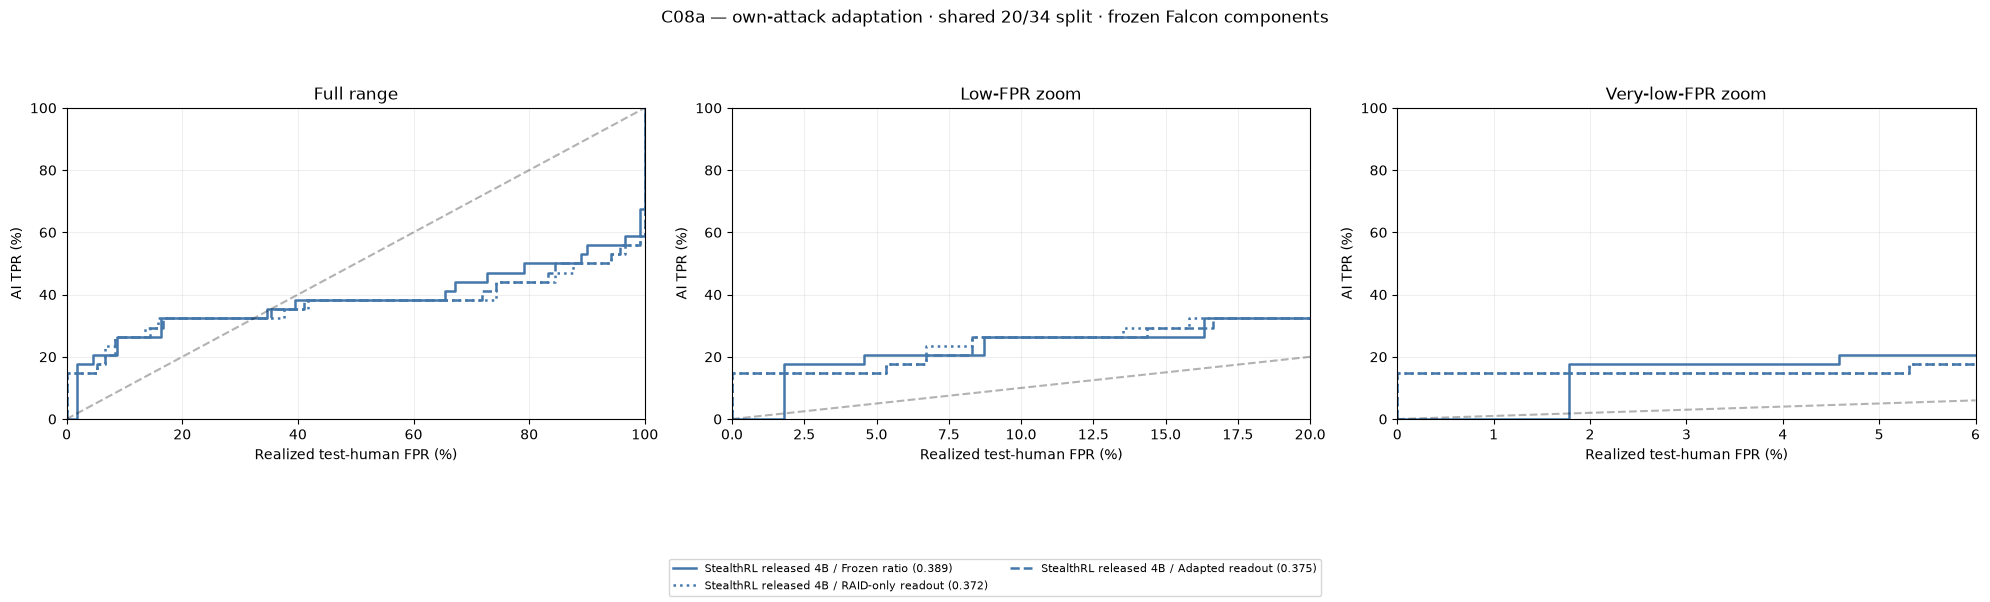

Saved: ../results/causal/C08a_Binoculars_competitors_NF4_v1
Intervals hold models, split and human references fixed. NF4 variant; adaptation changes the readout, not Falcon.


In [9]:
# No Falcon fine-tuning: match C07a's two-component logistic readout adaptation.
assert set(T.label.astype(int))=={0,1}
scaler=StandardScaler().fit(T[FEATURES])

def fit_readout(frame):
    model=LogisticRegression(C=1.0,class_weight='balanced',solver='lbfgs',
        max_iter=5000,random_state=ADAPT_SEED)
    with warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        model.fit(scaler.transform(frame[FEATURES]),frame.label.astype(int))
    return model

protocol=dict(features=FEATURES,seed=ADAPT_SEED,C=1.0,class_weight='balanced',
    scaler='original RAID train only',score_signature=signature,
    adaptation_cases=chosen,test_cases=held,selected=selected)
freeze(protocol,ADAPT/'adaptation_protocol.json')
# Persist fitted estimators atomically; fitting is CPU-only and inexpensive.
def persist_model(model,path):
    tmp=path.with_suffix('.tmp');joblib.dump(dict(model=model,scaler=scaler,protocol=protocol),tmp)
    os.replace(tmp,path)

all_rows=[];all_curves=[];all_stairs=[];all_ops=[];all_changes=[]
if selected:
    rp=ADAPT/'RAID_only_readout.joblib'
    if rp.exists():
        saved=joblib.load(rp);assert saved['protocol']==protocol
        np.testing.assert_array_equal(saved['scaler'].mean_,scaler.mean_)
        raid_model=saved['model']
    else:
        raid_model=fit_readout(T);persist_model(raid_model,rp)

for arm in selected:
    folder=ADAPT/arm;folder.mkdir(exist_ok=True)
    a=scored.loc[scored.stage.eq(arm)&scored.case_id.isin(chosen)].copy()
    e=scored.loc[scored.stage.eq(arm)&scored.case_id.isin(held)].sort_values('case_id').copy()
    assert len(a)==20 and len(e)==34
    fitting=pd.concat([T,a],ignore_index=True)
    assert not set(fitting.text_sha)&set(pd.concat([e,H]).text_sha), 'Exact text leakage: inspect inputs.'
    save_csv(fitting[['source_id','stage','text_sha','label',*FEATURES]],folder/'training_manifest.csv')
    mp=folder/'adapted_readout.joblib'
    if mp.exists():
        saved=joblib.load(mp);assert saved['protocol']==protocol
        adapted=saved['model']
        print(arm,': reused adapted readout')
    else:
        adapted=fit_readout(fitting);persist_model(adapted,mp)
        print(arm,': fitted original RAID train + 20 own-arm examples')
    v,h=references(e);contributions={};export=e.copy()
    hv=h.copy();vv=v.copy()
    for name,model in [('Frozen ratio',None),('RAID-only readout',raid_model),('Adapted readout',adapted)]:
        def score(f):return f.AI_score.to_numpy(float) if model is None else model.decision_function(scaler.transform(f[FEATURES]))
        av,vs,hs=score(e),score(v),score(h)
        row,st,c=measure(e,v,h,av,vs,hs,arm,name)
        contributions[name]=c;all_rows.append(row);all_stairs.append(st)
        all_curves.append((arm,name,st,row['AUROC']))
        export[name]=av;hv[name]=hs;vv[name]=vs
        for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1]:
            r=st.loc[st.calibration_FPR<=target+1e-12].iloc[-1].to_dict()
            all_ops.append(dict(target_FPR=target,**r))
    save_csv(export,folder/'heldout34_scores.csv')
    save_csv(hv,folder/'test_human_scores.csv');save_csv(vv,folder/'validation_human_scores.csv')
    ix=np.random.default_rng(ADAPT_SEED).integers(0,34,size=(5000,34))
    for left,right in [('Frozen ratio','Adapted readout'),('RAID-only readout','Adapted readout'),('Frozen ratio','RAID-only readout')]:
        d=contributions[right]-contributions[left];lo,hi=np.quantile(d[ix].mean(1),[.025,.975])
        all_changes.append(dict(arm=arm,comparison=right+' minus '+left,
            delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
if selected:
    adaptive_summary=pd.DataFrame(all_rows)
    for f,name in [(adaptive_summary,'adaptive34_summary.csv'),(pd.concat(all_stairs),'adaptive34_staircases.csv'),
        (pd.DataFrame(all_ops),'adaptive34_operating_points.csv'),(pd.DataFrame(all_changes),'adaptive34_paired_changes.csv')]:save_csv(f,ADAPT/name)
    display(adaptive_summary.round(6));display(pd.DataFrame(all_changes).round(6))
    plot_curves(all_curves,'C08a — own-attack adaptation · shared 20/34 split · frozen Falcon components',
        'C08a_Binoculars_NF4_adaptation34',COLORS)
else:print('No competitor met the <0.8 rule; no adapted models fitted.')
print('Saved:',ADAPT)
print('Intervals hold models, split and human references fixed. NF4 variant; adaptation changes the readout, not Falcon.')


In [10]:
# Append after C08a. After a restart, run its setup/data/contract/metric/model-definition
# cells first (through load_model/forward); then run these four cells.
required=['ROOT','OUT','docs','ns','signature','complete','load_model','forward','entropy','perplexity']
assert all(k in globals() for k in required), 'Run the original C08a setup through load_model/forward first.'
BASE_ADAPT=ROOT/'results/causal/C08a_Binoculars_competitors_NF4_v1'
ADAPT=BASE_ADAPT/'RAFT_NS11_extension_v1'
ADAPT.mkdir(parents=True,exist_ok=True)
# Keep the old scoring contract and cache; use a new directory for extended tables/models.
assert json.loads((OUT/'contract.json').read_text())==contract
assert signature==text_sha(json.dumps(contract,sort_keys=True))
assert contract['runtime']=={p:importlib.metadata.version(p) for p in contract['runtime']}, 'Restore the C08a scoring environment before scoring new texts.'
split=json.loads((BASE_ADAPT/'split.json').read_text())
chosen=split['adaptation_cases'];held=split['test_cases']
case_ids=sorted(ns.case_id.astype(str))
assert len(chosen)==20 and len(held)==34 and not set(chosen)&set(held)
assert set(chosen)|set(held)==set(case_ids)
freeze(split,ADAPT/'split.json')
NEW_FILES={
 'OG_RAFT':ROOT/'results/causal/R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv',
 'NS11':ROOT/'results/causal/R11_NS10_RAFT_v1/NS11_texts.csv',
}
extra=[];manifest=[]
for arm,path in NEW_FILES.items():
 assert path.exists(),f'Missing 54-case export: {path}'
 f=pd.read_csv(path,keep_default_na=False)
 assert len(f)==54 and f.case_id.is_unique and set(f.case_id)==set(ns.case_id)
 f=f.set_index('case_id').loc[ns.case_id].reset_index()
 assert f.source_id.astype(str).tolist()==ns.source_id.astype(str).tolist()
 assert f.domain.tolist()==ns.domain.tolist() and f.text.str.strip().ne('').all()
 if 'text_sha' in f:assert f.text_sha.eq(f.text.map(text_sha)).all()
 extra.append(f[['case_id','source_id','domain','text']].assign(stage=arm,split='test',label=1))
 manifest.extend(dict(arm=arm,case_id=r.case_id,text_sha=text_sha(r.text)) for r in f.itertuples())
freeze(manifest,ADAPT/'rewrite_inputs.json')
docs=pd.concat([docs.loc[~docs.stage.isin(NEW_FILES)],*extra],ignore_index=True)
docs['text_sha']=docs.text.map(text_sha);docs['words']=docs.text.str.split().str.len()
unique=docs[['text_sha','text','words']].drop_duplicates('text_sha').reset_index(drop=True)
lengths={r.text_sha:len(tok(r.text,truncation=False)['input_ids']) for r in unique.itertuples()}
assert min(lengths.values())>=2
docs['total_tokens']=docs.text_sha.map(lengths)
docs['scored_tokens']=docs.total_tokens.clip(upper=MAX_TOKENS)
docs['truncated']=docs.total_tokens.gt(MAX_TOKENS)
save_csv(docs.drop(columns='text'),ADAPT/'score_manifest.csv')
ARMS=['HIP_RAID_0.6B','MASH_RAID_GB','UTS_SYNTH_RECON','UTS_STREAM_RECON',
      'HIP_RELEASED_4B','StealthRL_RELEASED_4B','OG_RAFT','NS11']
LABELS.update({'OG_RAFT':'OG → RAFT','NS11':'NS11','NS10':'NS10'})
display(docs.groupby('stage').agg(documents=('text_sha','size'),truncated=('truncated','sum')))
print('Missing unique scores:',sum(not complete(s) for s in unique.text_sha))
print('Existing scores reused. Extension outputs:',ADAPT)


Token indices sequence length is longer than the specified maximum sequence length for this model (2969 > 2048). Running this sequence through the model will result in indexing errors


,documents,truncated
stage,,
HIP_RAID_0.6B,54,17
HIP_RELEASED_4B,54,6
Human,273,11
MASH_RAID_GB,54,8
NS10,54,25
NS11,54,25
OG,54,1
OG_RAFT,54,1
RAID_train,1272,51


Missing unique scores: 108
Existing scores reused. Extension outputs: ../results/causal/C08a_Binoculars_competitors_NF4_v1/RAFT_NS11_extension_v1


In [11]:
import fcntl
with (OUT/'binoculars_scoring.lock').open('a') as score_lock:
    fcntl.flock(score_lock,fcntl.LOCK_EX | fcntl.LOCK_NB)
    # Alternate model passes over bounded batches; final scores retain the same contract.
    # Existing completed scores and observer logits are reusable.
    all_pending=[r for r in unique.to_dict('records') if not complete(r['text_sha'])]
    for start in range(0,len(all_pending),SCORE_BATCH_SIZE):
     batch=all_pending[start:start+SCORE_BATCH_SIZE]
     print(f'Batch {start//SCORE_BATCH_SIZE+1}: {len(batch)} documents',flush=True)
     observer_pending=[r for r in batch if not complete(r['text_sha']) and not logit_path(r['text_sha']).exists()]
     needed=sum(min(lengths[r['text_sha']],MAX_TOKENS)*vocab*4 for r in observer_pending)
     assert shutil.disk_usage(OUT).free>needed+2*2**30,'Disk space low; reduce SCORE_BATCH_SIZE and rerun.'
     model=None
     try:
      if observer_pending:model=load_model(OBSERVER)
      for r in tqdm(observer_pending,desc='Observer batch'):
       enc=encode(r['text']);p=forward(model,enc)
       save_tensor(dict(contract=signature,text_sha=r['text_sha'],ids=enc.input_ids,logits=p),logit_path(r['text_sha']))
       del p,enc
     finally:
      del model;gc.collect();torch.cuda.empty_cache()
     model=None
     try:
      pending=[r for r in batch if not complete(r['text_sha'])]
      if pending:model=load_model(PERFORMER)
      for r in tqdm(pending,desc='Performer batch'):
       started=time.perf_counter();enc=encode(r['text'])
       saved=torch.load(logit_path(r['text_sha']),map_location='cpu',weights_only=True)
       assert saved['contract']==signature and saved['text_sha']==r['text_sha']
       assert torch.equal(saved['ids'],enc.input_ids)
       q=forward(model,enc);p=saved['logits']
       with torch.inference_mode():
        numerator=float(perplexity(enc,q)[0]);denominator=float(entropy(p,q,enc,tok.pad_token_id)[0])
       assert np.isfinite(numerator) and np.isfinite(denominator) and denominator>0
       ratio=numerator/denominator
       save_json(dict(contract=signature,text_sha=r['text_sha'],Binoculars_score=ratio,AI_score=-ratio,
        mean_nll=numerator,cross_entropy=denominator,scored_tokens=int(enc.input_ids.shape[1]),
        total_tokens=lengths[r['text_sha']],seconds=time.perf_counter()-started),cache_path(r['text_sha']))
       # Delete only after the final score is durably saved.
       logit_path(r['text_sha']).unlink(missing_ok=True)
       del p,q,enc,saved
     finally:
      del model;gc.collect();torch.cuda.empty_cache()
     print(f'Completed {min(start+SCORE_BATCH_SIZE,len(all_pending))}/{len(all_pending)} initially pending scores',flush=True)
    records=[]
    for r in docs.drop(columns='text').to_dict('records'):
     assert complete(r['text_sha'])
     records.append({**r,**json.loads(cache_path(r['text_sha']).read_text())})
    scored=pd.DataFrame(records);save_csv(scored,ADAPT/'all_scores.csv')
    print('Saved training and evaluation component scores.')


Batch 1: 32 documents
Loading tiiuae/falcon-7b


Loading checkpoint shards: 100%|███████████████████████████████████████████████████████████████| 2/2 [00:06<00:00,  3.30s/it]

Model footprint: 3.65 GiB



Observer batch: 100%|████████████████████████████████████████████████████████████████████████| 32/32 [00:12<00:00,  2.60it/s]


Loading tiiuae/falcon-7b-instruct


...

Loading tiiuae/falcon-7b-instruct


Loading checkpoint shards: 100%|███████████████████████████████████████████████████████████████| 2/2 [00:06<00:00,  3.04s/it]

Model footprint: 3.65 GiB



Performer batch: 100%|███████████████████████████████████████████████████████████████████████| 12/12 [00:08<00:00,  1.43it/s]


Completed 108/108 initially pending scores
Saved training and evaluation component scores.


,arm,detector,cases,AUROC,mean_AI_score
0,OG,Frozen ratio,54,0.905163,-0.765013
1,NS10,Frozen ratio,54,0.721606,-0.919246
2,HIP_RAID_0.6B,Frozen ratio,54,0.892028,-0.818187
3,MASH_RAID_GB,Frozen ratio,54,0.851328,-0.893905
4,UTS_SYNTH_RECON,Frozen ratio,54,0.879499,-0.845388
5,UTS_STREAM_RECON,Frozen ratio,54,0.965326,-0.783344
6,HIP_RELEASED_4B,Frozen ratio,54,0.918052,-0.856037
7,StealthRL_RELEASED_4B,Frozen ratio,54,0.381898,-1.031138
8,OG_RAFT,Frozen ratio,54,0.661527,-0.955590
9,NS11,Frozen ratio,54,0.534750,-0.979045


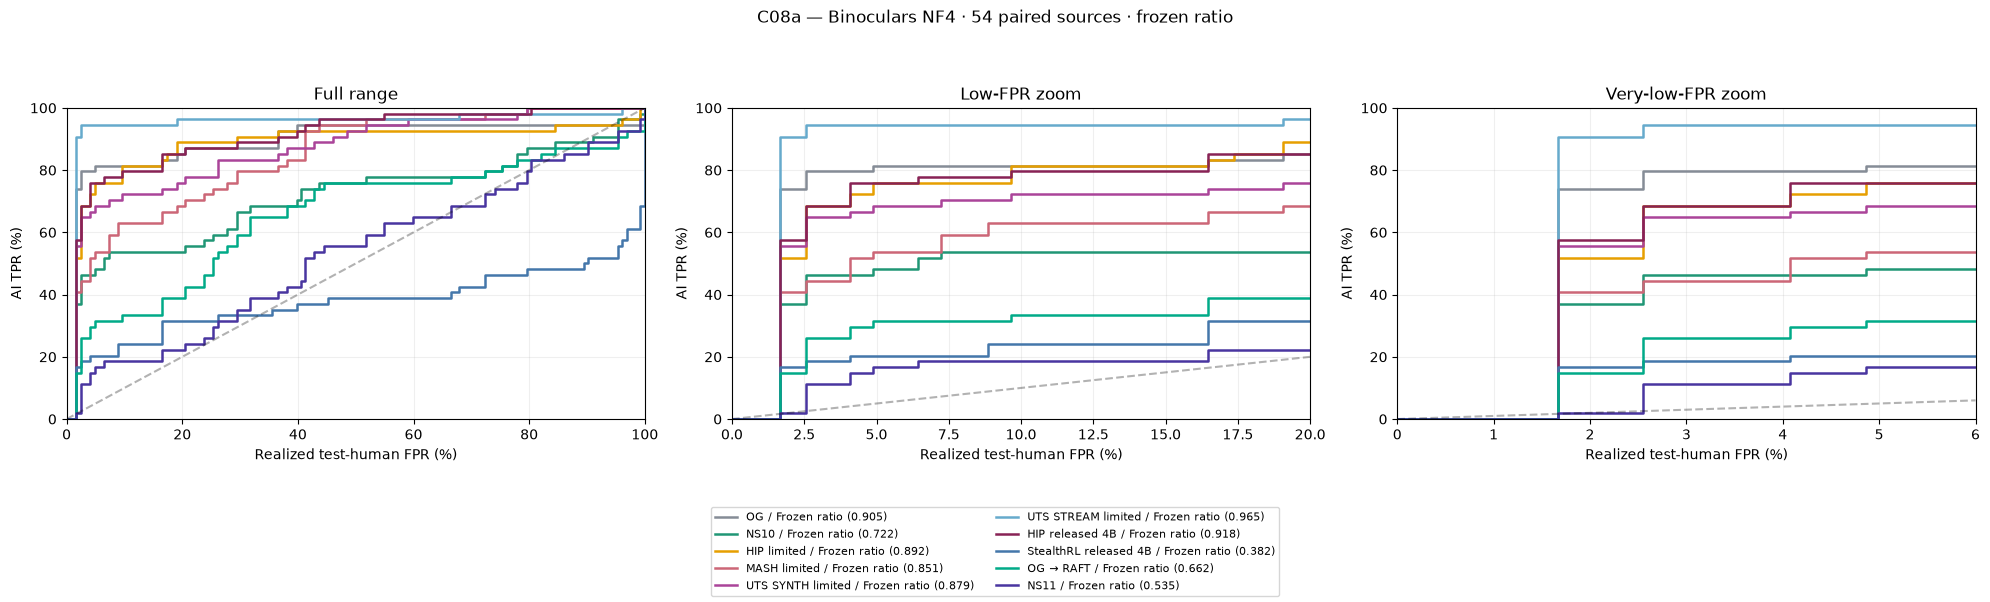

,arm,reference,delta_AUROC,ci_low,ci_high
0,HIP_RAID_0.6B,OG,-0.013135,-0.096163,0.070868
1,HIP_RAID_0.6B,NS10,0.170422,0.062185,0.274545
2,HIP_RAID_0.6B,StealthRL_RELEASED_4B,0.510130,0.386671,0.625098
3,MASH_RAID_GB,OG,-0.053835,-0.136290,0.030931
4,MASH_RAID_GB,NS10,0.129721,0.027631,0.231653
5,MASH_RAID_GB,StealthRL_RELEASED_4B,0.469430,0.345318,0.585306
6,UTS_SYNTH_RECON,OG,-0.025664,-0.080972,0.029713
7,UTS_SYNTH_RECON,NS10,0.157893,0.072771,0.247417
8,UTS_SYNTH_RECON,StealthRL_RELEASED_4B,0.497601,0.383464,0.603834
9,UTS_STREAM_RECON,OG,0.060164,0.004065,0.125149


Selected for own-attack adaptation: ['NS10', 'StealthRL_RELEASED_4B', 'OG_RAFT', 'NS11']
Selection uses all 54 scores: subsequent 34-case adaptation analysis is exploratory, not an independent selection holdout.


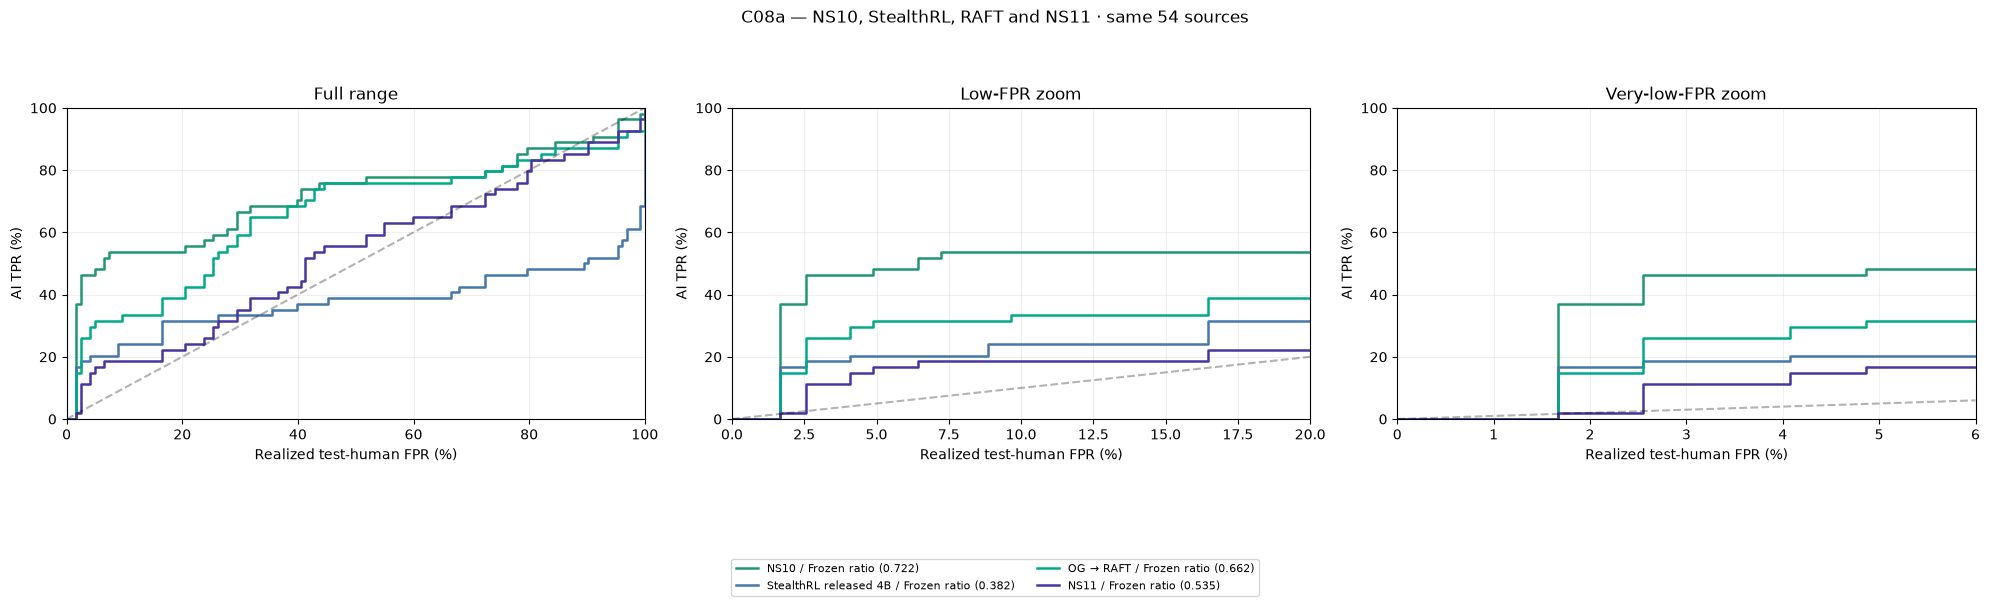

Paired comparisons against StealthRL; negative favors the listed arm under the frozen score:


,arm,reference,delta_AUROC,ci_low,ci_high
2,HIP_RAID_0.6B,StealthRL_RELEASED_4B,0.510130,0.386671,0.625098
5,MASH_RAID_GB,StealthRL_RELEASED_4B,0.469430,0.345318,0.585306
8,UTS_SYNTH_RECON,StealthRL_RELEASED_4B,0.497601,0.383464,0.603834
11,UTS_STREAM_RECON,StealthRL_RELEASED_4B,0.583428,0.467255,0.694160
14,HIP_RELEASED_4B,StealthRL_RELEASED_4B,0.536154,0.427336,0.641623
19,OG_RAFT,StealthRL_RELEASED_4B,0.279629,0.186041,0.374871
22,NS11,StealthRL_RELEASED_4B,0.152852,0.033086,0.269366


In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
import warnings
import joblib

H=scored.loc[scored.stage.eq('Human')].copy()
T=scored.loc[scored.stage.eq('RAID_train')].copy()
FEATURES=['mean_nll','cross_entropy']
assert np.isfinite(scored[FEATURES].to_numpy(float)).all()

def references(e):
    mix=e.domain.value_counts(normalize=True)
    def get(split):
        f=H.loc[H.split.eq(split)&H.domain.isin(mix.index)].copy()
        counts=f.domain.value_counts()
        assert set(mix.index)<=set(counts.index)
        f['weight']=[mix[d]/counts[d] for d in f.domain]
        assert np.isclose(f.weight.sum(),1)
        return f
    return get('validation'),get('test')

def measure(e,v,h,ai,vs,hs,arm,detector):
    w=h.weight.to_numpy();cw=v.weight.to_numpy()
    contribution=((ai[:,None]>hs)+.5*(ai[:,None]==hs))@w
    cuts=np.r_[np.inf,np.unique(vs)[::-1],-np.inf]
    st=pd.DataFrame(dict(arm=arm,detector=detector,threshold=cuts,
        calibration_FPR=[cw[vs>c].sum() for c in cuts],
        test_FPR=[w[hs>c].sum() for c in cuts],TPR=[(ai>c).mean() for c in cuts]))
    row=dict(arm=arm,detector=detector,cases=len(e),AUROC=float(contribution.mean()),
        mean_AI_score=float(ai.mean()))
    return row,st,contribution

def plot_curves(curves,title,stem,colors):
    fig,axes=plt.subplots(1,3,figsize=(20,6))
    for ax,(xl,yl,name) in zip(axes,[((0,100),(0,100),'Full range'),
        ((0,20),(0,100),'Low-FPR zoom'),((0,6),(0,100),'Very-low-FPR zoom')]):
        for arm,detector,st,value in curves:
            style={'Frozen ratio':'-','RAID-only readout':':','Adapted readout':'--'}[detector]
            ax.step(st.test_FPR*100,st.TPR*100,where='post',lw=1.8,color=colors[arm],
                linestyle=style,label=f'{LABELS.get(arm,arm)} / {detector} ({value:.3f})')
        ax.plot([0,xl[1]],[0,xl[1]],'k--',alpha=.3)
        ax.set(xlim=xl,ylim=yl,title=name,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)')
        ax.grid(alpha=.2)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',ncol=2,fontsize=8)
    fig.suptitle(title)
    fig.tight_layout(rect=[0,.20,1,.93])
    for folder in [ADAPT,ROOT/'figures']:
        folder.mkdir(parents=True,exist_ok=True)
        for ext in ['png','pdf']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)

COLORS=dict(zip(['OG','NS10',*ARMS],['#858C96','#209675','#E69F00','#CC6677','#AA4499','#66AACC','#882255','#4477AA','#00AA88','#4935A0']))
rows=[];curves=[];stairs=[];full_contrib={}
for arm in ['OG','NS10',*ARMS]:
    e=scored.loc[scored.stage.eq(arm)].sort_values('case_id').copy()
    assert len(e)==54 and e.case_id.tolist()==case_ids
    v,h=references(e)
    row,st,c=measure(e,v,h,e.AI_score.to_numpy(),v.AI_score.to_numpy(),h.AI_score.to_numpy(),arm,'Frozen ratio')
    rows.append(row);stairs.append(st);curves.append((arm,'Frozen ratio',st,row['AUROC']));full_contrib[arm]=c
full_summary=pd.DataFrame(rows)
save_csv(full_summary,ADAPT/'frozen54_summary.csv')
save_csv(pd.concat(stairs),ADAPT/'frozen54_staircase.csv')
display(full_summary.round(6))
plot_curves(curves,'C08a — Binoculars NF4 · 54 paired sources · frozen ratio',
    'C08a_Binoculars_NF4_RAFT_NS11_frozen54',COLORS)
# Paired intervals conditional on the fixed human reference and score extractor.
draws=np.random.default_rng(ADAPT_SEED).integers(0,54,size=(5000,54));changes=[]
for arm in ARMS:
    for ref in ['OG','NS10','StealthRL_RELEASED_4B']:
        if arm==ref:continue
        d=full_contrib[arm]-full_contrib[ref];lo,hi=np.quantile(d[draws].mean(1),[.025,.975])
        changes.append(dict(arm=arm,reference=ref,delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
save_csv(pd.DataFrame(changes),ADAPT/'frozen54_paired_changes.csv')
display(pd.DataFrame(changes).round(6))
selected=full_summary.loc[full_summary.arm.isin(['NS10',*ARMS])&full_summary.AUROC.lt(.8),'arm'].tolist()
freeze(dict(rule='non-OG full54 frozen-ratio AUROC < 0.8',selected=selected),ADAPT/'selected_arms.json')
print('Selected for own-attack adaptation:',selected or 'None')
print('Selection uses all 54 scores: subsequent 34-case adaptation analysis is exploratory, not an independent selection holdout.')

focus=['NS10','StealthRL_RELEASED_4B','OG_RAFT','NS11']
plot_curves([x for x in curves if x[0] in focus],
    'C08a — NS10, StealthRL, RAFT and NS11 · same 54 sources',
    'C08a_Binoculars_NF4_RAFT_NS11_focus54',COLORS)
print('Paired comparisons against StealthRL; negative favors the listed arm under the frozen score:')
display(pd.DataFrame(changes).query("reference == 'StealthRL_RELEASED_4B'").round(6))


NS10 : fitted original RAID train + 20 own-arm examples
StealthRL_RELEASED_4B : fitted original RAID train + 20 own-arm examples
OG_RAFT : fitted original RAID train + 20 own-arm examples
NS11 : fitted original RAID train + 20 own-arm examples


,arm,detector,cases,AUROC,mean_AI_score
0,NS10,Frozen ratio,34,0.684260,-0.928848
1,NS10,RAID-only readout,34,0.672084,-0.642170
2,NS10,Adapted readout,34,0.678159,-0.582445
3,StealthRL_RELEASED_4B,Frozen ratio,34,0.389499,-1.027403
4,StealthRL_RELEASED_4B,RAID-only readout,34,0.372399,-3.219457
5,StealthRL_RELEASED_4B,Adapted readout,34,0.375363,-2.718132
6,OG_RAFT,Frozen ratio,34,0.712858,-0.946518
7,OG_RAFT,RAID-only readout,34,0.705645,-1.064727
8,OG_RAFT,Adapted readout,34,0.715062,-0.928698
9,NS11,Frozen ratio,34,0.508704,-0.983952


,arm,comparison,delta_AUROC,ci_low,ci_high
0,NS10,Adapted readout minus Frozen ratio,-0.006100,-0.016848,0.003228
1,NS10,Adapted readout minus RAID-only readout,0.006075,0.001968,0.011251
2,NS10,RAID-only readout minus Frozen ratio,-0.012175,-0.025159,-0.000821
3,StealthRL_RELEASED_4B,Adapted readout minus Frozen ratio,-0.014136,-0.025389,-0.003480
4,StealthRL_RELEASED_4B,Adapted readout minus RAID-only readout,0.002964,-0.000167,0.006823
5,StealthRL_RELEASED_4B,RAID-only readout minus Frozen ratio,-0.017100,-0.029627,-0.006175
6,OG_RAFT,Adapted readout minus Frozen ratio,0.002204,-0.012463,0.014128
7,OG_RAFT,Adapted readout minus RAID-only readout,0.009417,0.005035,0.014371
8,OG_RAFT,RAID-only readout minus Frozen ratio,-0.007213,-0.022765,0.005330
9,NS11,Adapted readout minus Frozen ratio,0.008401,-0.011555,0.028154


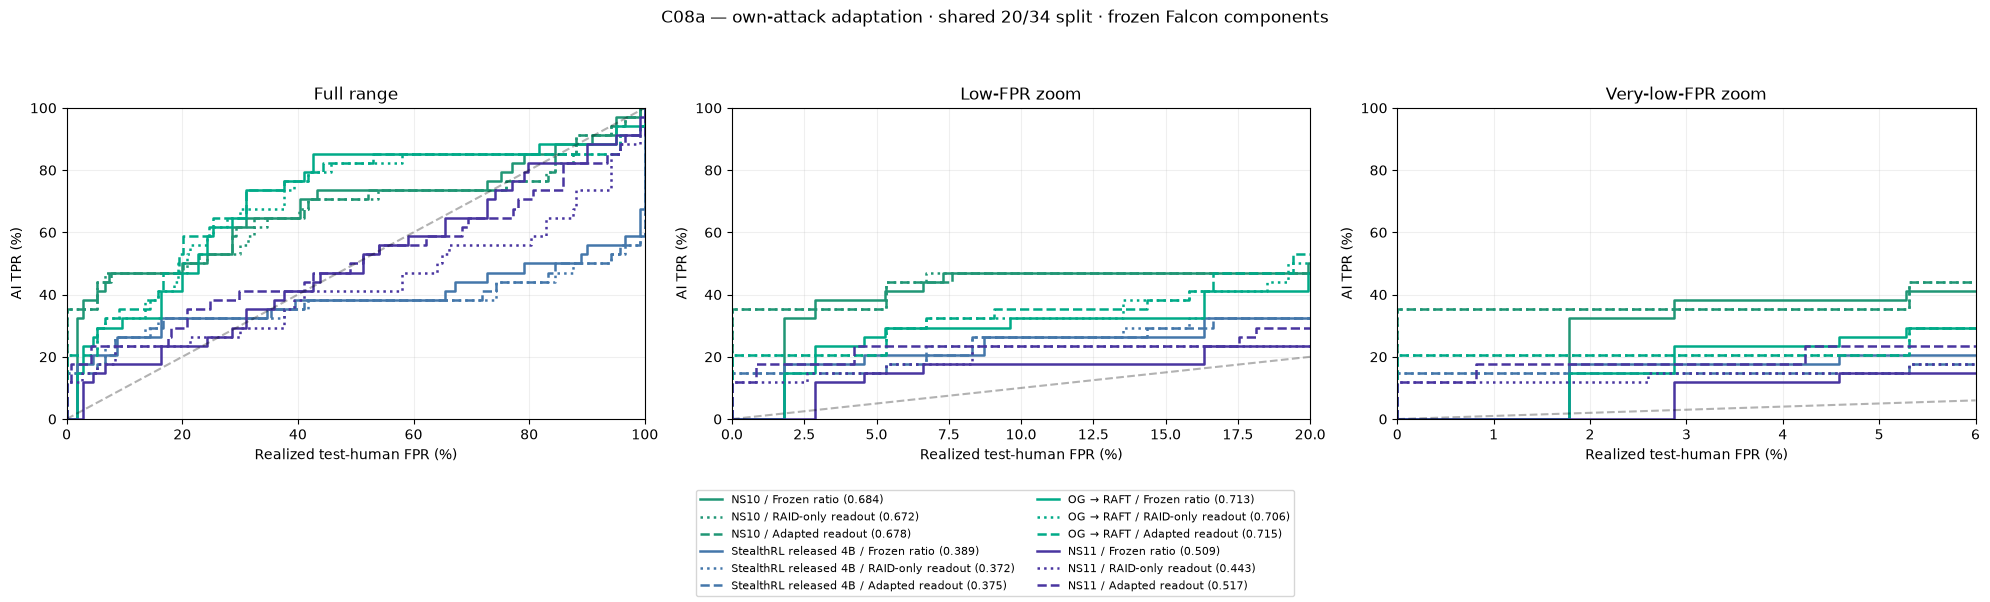

Saved: ../results/causal/C08a_Binoculars_competitors_NF4_v1/RAFT_NS11_extension_v1
Intervals hold models, split and human references fixed. NF4 variant; adaptation changes the readout, not Falcon.


In [13]:
# No Falcon fine-tuning: match C07a's two-component logistic readout adaptation.
assert set(T.label.astype(int))=={0,1}
scaler=StandardScaler().fit(T[FEATURES])

def fit_readout(frame):
    model=LogisticRegression(C=1.0,class_weight='balanced',solver='lbfgs',
        max_iter=5000,random_state=ADAPT_SEED)
    with warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        model.fit(scaler.transform(frame[FEATURES]),frame.label.astype(int))
    return model

protocol=dict(features=FEATURES,seed=ADAPT_SEED,C=1.0,class_weight='balanced',
    scaler='original RAID train only',score_signature=signature,
    adaptation_cases=chosen,test_cases=held,selected=selected)
freeze(protocol,ADAPT/'adaptation_protocol.json')
# Persist fitted estimators atomically; fitting is CPU-only and inexpensive.
def persist_model(model,path):
    tmp=path.with_suffix('.tmp');joblib.dump(dict(model=model,scaler=scaler,protocol=protocol),tmp)
    os.replace(tmp,path)

all_rows=[];all_curves=[];all_stairs=[];all_ops=[];all_changes=[]
if selected:
    rp=ADAPT/'RAID_only_readout.joblib'
    if rp.exists():
        saved=joblib.load(rp);assert saved['protocol']==protocol
        np.testing.assert_array_equal(saved['scaler'].mean_,scaler.mean_)
        raid_model=saved['model']
    else:
        raid_model=fit_readout(T);persist_model(raid_model,rp)

for arm in selected:
    folder=ADAPT/arm;folder.mkdir(exist_ok=True)
    a=scored.loc[scored.stage.eq(arm)&scored.case_id.isin(chosen)].copy()
    e=scored.loc[scored.stage.eq(arm)&scored.case_id.isin(held)].sort_values('case_id').copy()
    assert len(a)==20 and len(e)==34
    fitting=pd.concat([T,a],ignore_index=True)
    assert not set(fitting.text_sha)&set(pd.concat([e,H]).text_sha), 'Exact text leakage: inspect inputs.'
    save_csv(fitting[['source_id','stage','text_sha','label',*FEATURES]],folder/'training_manifest.csv')
    mp=folder/'adapted_readout.joblib'
    if mp.exists():
        saved=joblib.load(mp);assert saved['protocol']==protocol
        adapted=saved['model']
        print(arm,': reused adapted readout')
    else:
        adapted=fit_readout(fitting);persist_model(adapted,mp)
        print(arm,': fitted original RAID train + 20 own-arm examples')
    v,h=references(e);contributions={};export=e.copy()
    hv=h.copy();vv=v.copy()
    for name,model in [('Frozen ratio',None),('RAID-only readout',raid_model),('Adapted readout',adapted)]:
        def score(f):return f.AI_score.to_numpy(float) if model is None else model.decision_function(scaler.transform(f[FEATURES]))
        av,vs,hs=score(e),score(v),score(h)
        row,st,c=measure(e,v,h,av,vs,hs,arm,name)
        contributions[name]=c;all_rows.append(row);all_stairs.append(st)
        all_curves.append((arm,name,st,row['AUROC']))
        export[name]=av;hv[name]=hs;vv[name]=vs
        for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1]:
            r=st.loc[st.calibration_FPR<=target+1e-12].iloc[-1].to_dict()
            all_ops.append(dict(target_FPR=target,**r))
    save_csv(export,folder/'heldout34_scores.csv')
    save_csv(hv,folder/'test_human_scores.csv');save_csv(vv,folder/'validation_human_scores.csv')
    ix=np.random.default_rng(ADAPT_SEED).integers(0,34,size=(5000,34))
    for left,right in [('Frozen ratio','Adapted readout'),('RAID-only readout','Adapted readout'),('Frozen ratio','RAID-only readout')]:
        d=contributions[right]-contributions[left];lo,hi=np.quantile(d[ix].mean(1),[.025,.975])
        all_changes.append(dict(arm=arm,comparison=right+' minus '+left,
            delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
if selected:
    adaptive_summary=pd.DataFrame(all_rows)
    for f,name in [(adaptive_summary,'adaptive34_summary.csv'),(pd.concat(all_stairs),'adaptive34_staircases.csv'),
        (pd.DataFrame(all_ops),'adaptive34_operating_points.csv'),(pd.DataFrame(all_changes),'adaptive34_paired_changes.csv')]:save_csv(f,ADAPT/name)
    display(adaptive_summary.round(6));display(pd.DataFrame(all_changes).round(6))
    plot_curves(all_curves,'C08a — own-attack adaptation · shared 20/34 split · frozen Falcon components',
        'C08a_Binoculars_NF4_RAFT_NS11_adaptation34',COLORS)
else:print('No competitor met the <0.8 rule; no adapted models fitted.')
print('Saved:',ADAPT)
print('Intervals hold models, split and human references fixed. NF4 variant; adaptation changes the readout, not Falcon.')
